**Predicción multiclase de riesgo cardiovascular**

**Objetivo:** clasificar a los pacientes en tres niveles de riesgo cardiovascular a partir de 27 variables sociodemográficas, clínicas, analíticas y de estilo de vida.

| Clase | Significado |
|---|---|
| 0 | Bajo riesgo |
| 1 | Riesgo moderado |
| 2 | Alto riesgo |

**Dataset:** `data/enfermedad_cardiovascular.csv` (2.254 pacientes, 27 variables de entrada + 1 objetivo).

# Librerías
Importar las librerías necesarias y fijar la semilla para garantizar la reproducibilidad.

In [34]:
import pandas as pd
import seaborn as sns
import numpy as np
from matplotlib import pyplot as plt

%matplotlib inline

semilla=42
np.random.seed(semilla)

# 1. EDA

Objetivo de esta fase: auditar la calidad del dataset e identificar todas las problemáticas presentes en las variables (apartado 3.1 del enunciado).

## 1.1. Carga de datos

Cargar el CSV en un DataFrame.

In [35]:
url = ('../data/enfermedad_cardiovascular.csv')
datos = pd.read_csv(url, sep=',')
datos.head(3)

,edad,presion_sistolica,presion_diastolica,colesterol_total,colesterol_hdl,colesterol_ldl,trigliceridos,glucosa_ayunas,indice_masa_corporal,frecuencia_cardiaca_reposo,...,hemoglobina_glicosilada,fumador_actual,hipertension_previa,diabetes_mellitus,tratamiento_estatinas,uso_antihipertensivos,tipo_alimentacion,nivel_actividad,antecedentes_familiares_tipo,riesgo_cardiovascular
0,57.4,192.0,78.9,371.24,62.6,149.1,245.6,NaN,30.4,95.1,...,5.41,1,1,1,0,1,Mediterránea,Moderadamente activo,Ninguno,2
1,51.7,131.2,80.0,270.20,35.4,NaN,173.8,137.5,29.7,85.3,...,6.11,0,1,0,1,1,Baja en carbohidratos,Ligeramente activo,Ambos,1
2,56.7,127.1,92.5,202.30,47.7,134.1,60.9,157.4,29.4,87.5,...,6.52,1,1,0,0,1,Baja en carbohidratos,Sedentario,Ninguno,2


## 1.2. Descripción del dataset

Ver las dimensiones, tipos de datos, valores estadísticos y valores duplicados.



In [36]:
datos.info()
display(datos.describe(include='all').T)
display(datos.shape)
datos.duplicated().sum()
datos.isnull().sum()

<class 'pandas.DataFrame'>
RangeIndex: 2254 entries, 0 to 2253
Data columns (total 28 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   edad                          2254 non-null   float64
 1   presion_sistolica             2254 non-null   float64
 2   presion_diastolica            2254 non-null   float64
 3   colesterol_total              2254 non-null   float64
 4   colesterol_hdl                2254 non-null   float64
 5   colesterol_ldl                2119 non-null   float64
 6   trigliceridos                 2254 non-null   float64
 7   glucosa_ayunas                2142 non-null   float64
 8   indice_masa_corporal          2254 non-null   float64
 9   frecuencia_cardiaca_reposo    2254 non-null   float64
 10  horas_sueno_diarias           2074 non-null   float64
 11  consumo_alcohol_semanal       2254 non-null   float64
 12  anos_fumador                  2254 non-null   float64
 13  proteina_c_rea

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
edad,2254.0,NaN,NaN,NaN,56.688287,14.448018,9.8,47.2,56.9,66.475,103.5
presion_sistolica,2254.0,NaN,NaN,NaN,132.315186,26.931005,52.2,115.3,129.65,143.9,231.36
presion_diastolica,2254.0,NaN,NaN,NaN,82.167524,13.084058,30.8,73.6,82.1,91.1,122.5
colesterol_total,2254.0,NaN,NaN,NaN,228.133829,62.725948,61.1,188.2,221.2,252.5,448.59
colesterol_hdl,2254.0,NaN,NaN,NaN,47.2252,15.991614,-8.8,36.7,47.3,58.2,106.3
colesterol_ldl,2119.0,NaN,NaN,NaN,135.638603,36.732756,6.1,111.4,135.5,161.4,266.7
trigliceridos,2254.0,NaN,NaN,NaN,176.657391,72.735893,-35.7,133.05,170.0,208.1,452.7
glucosa_ayunas,2142.0,NaN,NaN,NaN,104.10733,24.939696,32.0,86.3,103.75,120.475,194.0
indice_masa_corporal,2254.0,NaN,NaN,NaN,28.09339,6.470585,3.6,23.8,28.0,32.5,50.6
frecuencia_cardiaca_reposo,2254.0,NaN,NaN,NaN,73.66819,12.762546,25.8,65.0,73.1,82.3,112.7


(2254, 28)

edad                              0
presion_sistolica                 0
presion_diastolica                0
colesterol_total                  0
colesterol_hdl                    0
colesterol_ldl                  135
trigliceridos                     0
glucosa_ayunas                  112
indice_masa_corporal              0
frecuencia_cardiaca_reposo        0
horas_sueno_diarias             180
consumo_alcohol_semanal           0
anos_fumador                      0
proteina_c_reactiva             157
acido_urico                       0
clearance_creatinina              0
frecuencia_ejercicio_semanal      0
perimetro_cintura                 0
hemoglobina_glicosilada           0
fumador_actual                    0
hipertension_previa               0
diabetes_mellitus                 0
tratamiento_estatinas             0
uso_antihipertensivos             0
tipo_alimentacion                 0
nivel_actividad                   0
antecedentes_familiares_tipo      0
riesgo_cardiovascular       

**Estructura general**
- Filas y columnas: 2254 filas y 28 columnas
- Duplicados: 0 registros duplicados
- Valores nulos: Columnas `colesterol_ldl` = 135, `glucosa_ayunas` = 112, `horas_sueno_diarias` = 180, y `proteina_c_reactiva` = 157.

**Anómalos**
- Mínimos anómalos: Registros negativos en `colesterol_hdl`, `trigliceridos` y `consumo_alcohol_semanal`, `indice_masa_corporal` = 3.6 incompatible con la vida humana 3.6 (un índice menor a 10 u 11 se consideraría severamente crítico), `edad` = 9.8 no es adulto.
- Máximos anómalos: `frecuencia_ejercicio_semanal` mayor a 7 días de la semana,

**Posibles outliers**
- Valores a comprobar clínicamente: `presion_sistolica` = 231.36, `presion_diastolica` = 122.5, `colesterol_total` = 448.59, `trigliceridos` = 452.7, `proteinca_c_reactiva` = 12.88, `acido_urico` = 12.29, `horas_sueno_diarias` = 1.6.


## 1.3. Distribuciones

Visualizar distribución de los datos

### 1.3.1 Variables continuas

<Axes: >

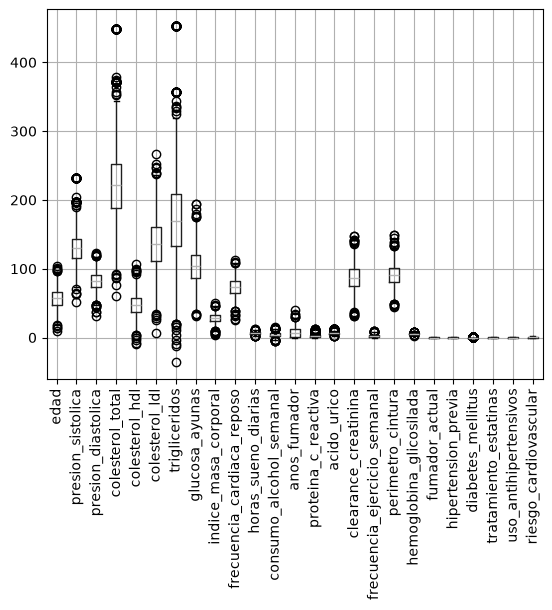

In [37]:
datos.boxplot(rot=90)

C:\Users\rodma\AppData\Local\Temp\ipykernel_1528\4264787754.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=datos, x="riesgo_cardiovascular", y=variable, palette="Dark2")
C:\Users\rodma\AppData\Local\Temp\ipykernel_1528\4264787754.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=datos, x="riesgo_cardiovascular", y=variable, palette="Dark2")
C:\Users\rodma\AppData\Local\Temp\ipykernel_1528\4264787754.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=datos, x="riesgo_cardiovascular", y=variable, palette="Dark2")
C:\U

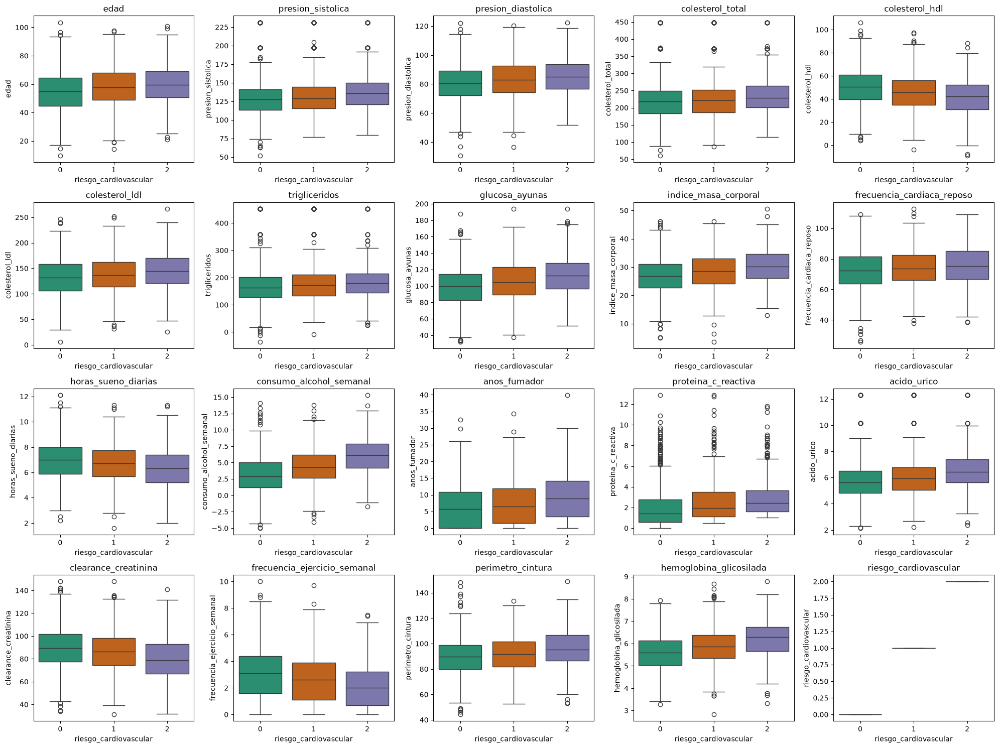

In [38]:
variables_continuas = [
    "edad",
    "presion_sistolica",
    "presion_diastolica",
    "colesterol_total",
    "colesterol_hdl",
    "colesterol_ldl",
    "trigliceridos",
    "glucosa_ayunas",
    "indice_masa_corporal",
    "frecuencia_cardiaca_reposo",
    "horas_sueno_diarias",
    "consumo_alcohol_semanal",
    "anos_fumador",
    "proteina_c_reactiva",
    "acido_urico",
    "clearance_creatinina",
    "frecuencia_ejercicio_semanal",
    "perimetro_cintura",
    "hemoglobina_glicosilada",
    "riesgo_cardiovascular"
]

plt.figure(figsize=(20, 15))

for i, variable in enumerate(variables_continuas):
    plt.subplot(4, 5, i+1)
    sns.boxplot(data=datos, x="riesgo_cardiovascular", y=variable, palette="Dark2")
    plt.title(variable)

plt.tight_layout()
plt.show()

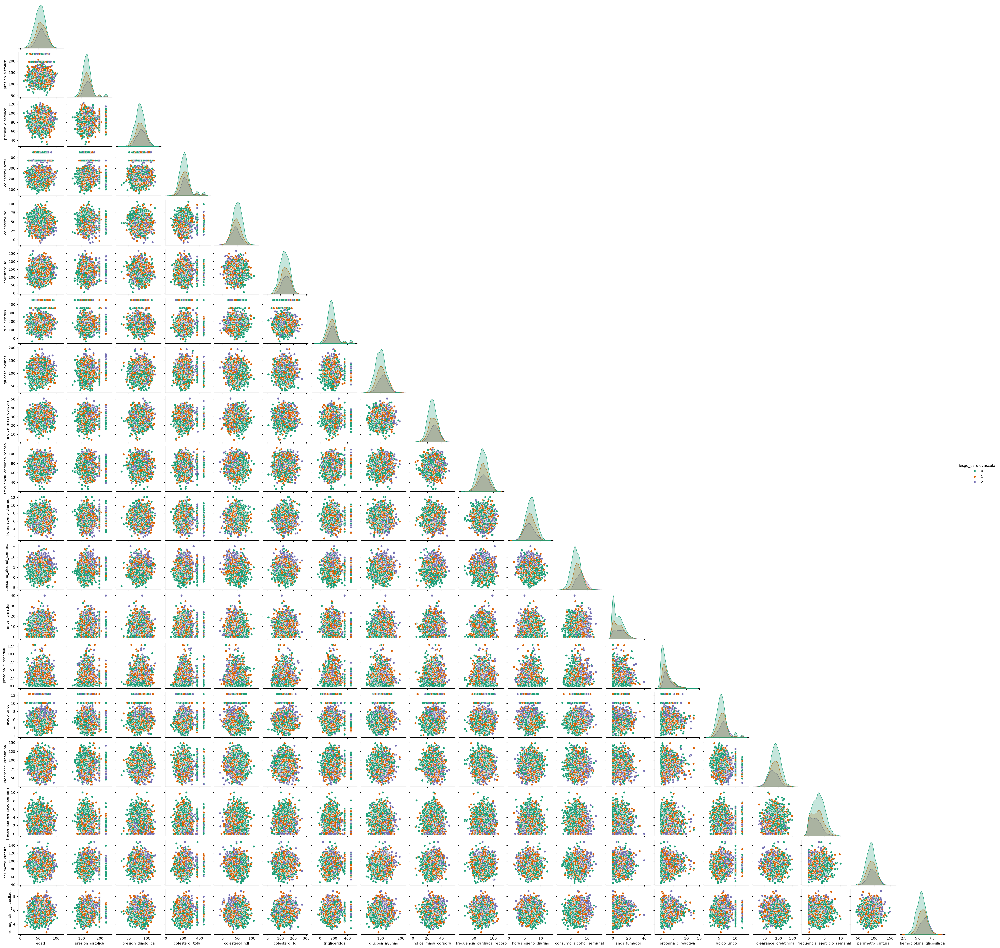

In [39]:
# Visualizar scatter en conjunto a distribuciones

sns.pairplot(datos[variables_continuas], hue="riesgo_cardiovascular", height=2, palette='Dark2', corner=True)

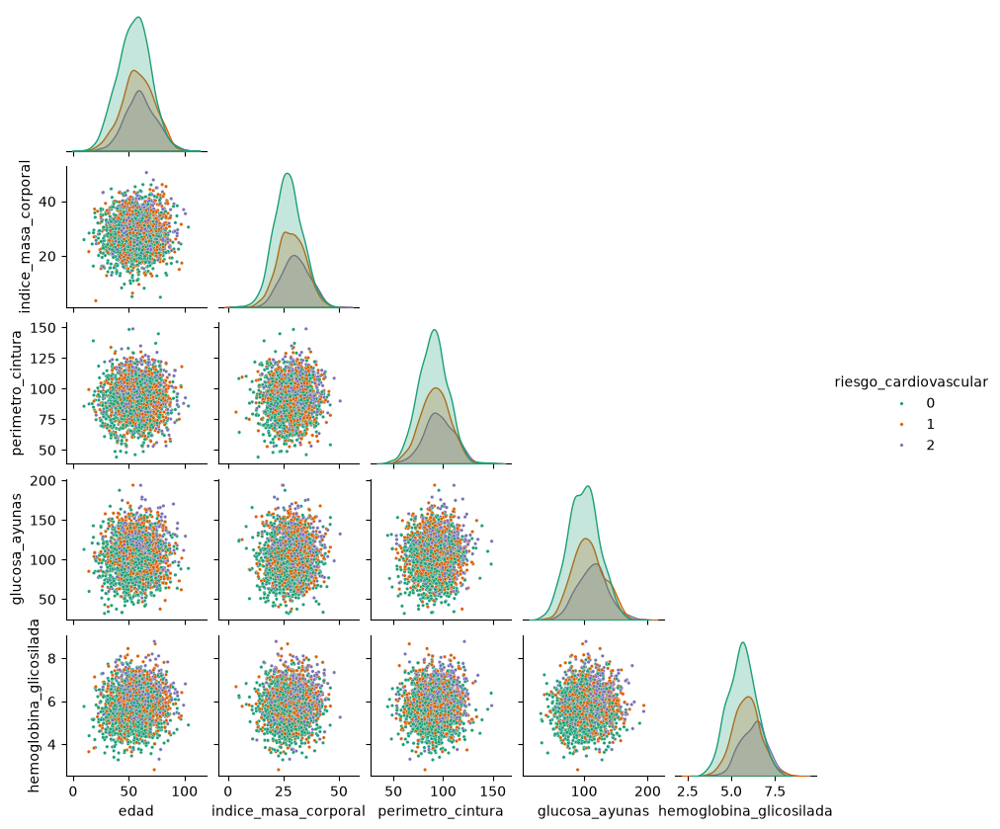

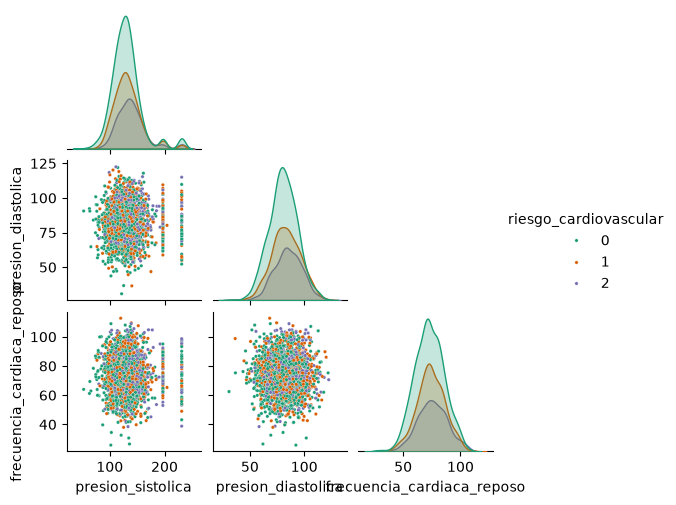

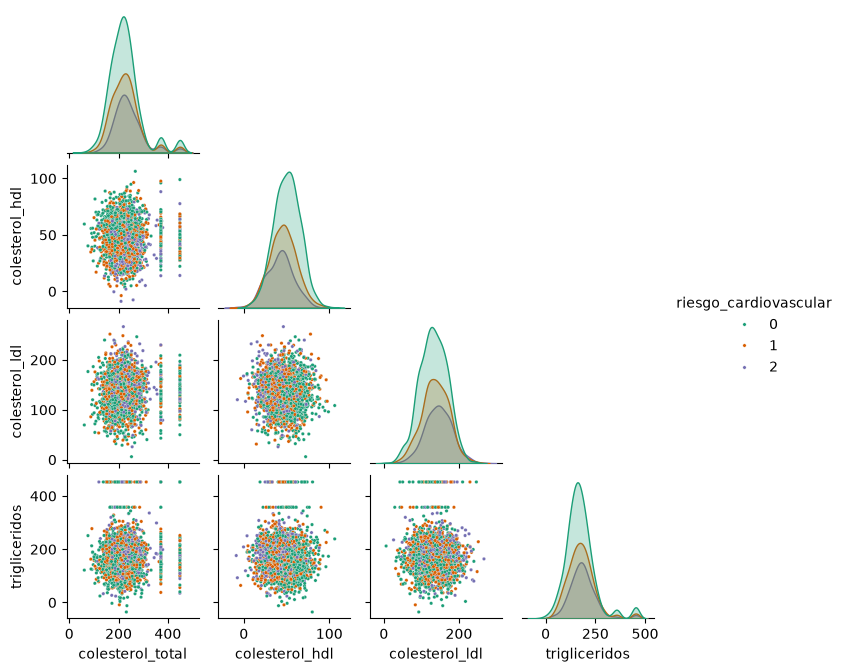

In [40]:
# Desagregar por tipo de perfil de acuerdo con variables relacionadas

# Perfil Físico y Metabólico
perfil_fisico = ["edad", "indice_masa_corporal", "perimetro_cintura", "glucosa_ayunas", "hemoglobina_glicosilada", "riesgo_cardiovascular"]
sns.pairplot(datos[perfil_fisico], hue="riesgo_cardiovascular", palette='Dark2', corner=True, height=1.7, plot_kws={'s': 6})

# Perfil Cardiovascular puro
perfil_cardio = ["presion_sistolica", "presion_diastolica", "frecuencia_cardiaca_reposo", "riesgo_cardiovascular"]
sns.pairplot(datos[perfil_cardio], hue="riesgo_cardiovascular", palette='Dark2', corner=True, height=1.7, plot_kws={'s': 6})

# Perfil de Lípidos
perfil_lipidos = ["colesterol_total", "colesterol_hdl", "colesterol_ldl", "trigliceridos", "riesgo_cardiovascular"]
sns.pairplot(datos[perfil_lipidos], hue="riesgo_cardiovascular", palette='Dark2',corner=True, height=1.7, plot_kws={'s': 6})


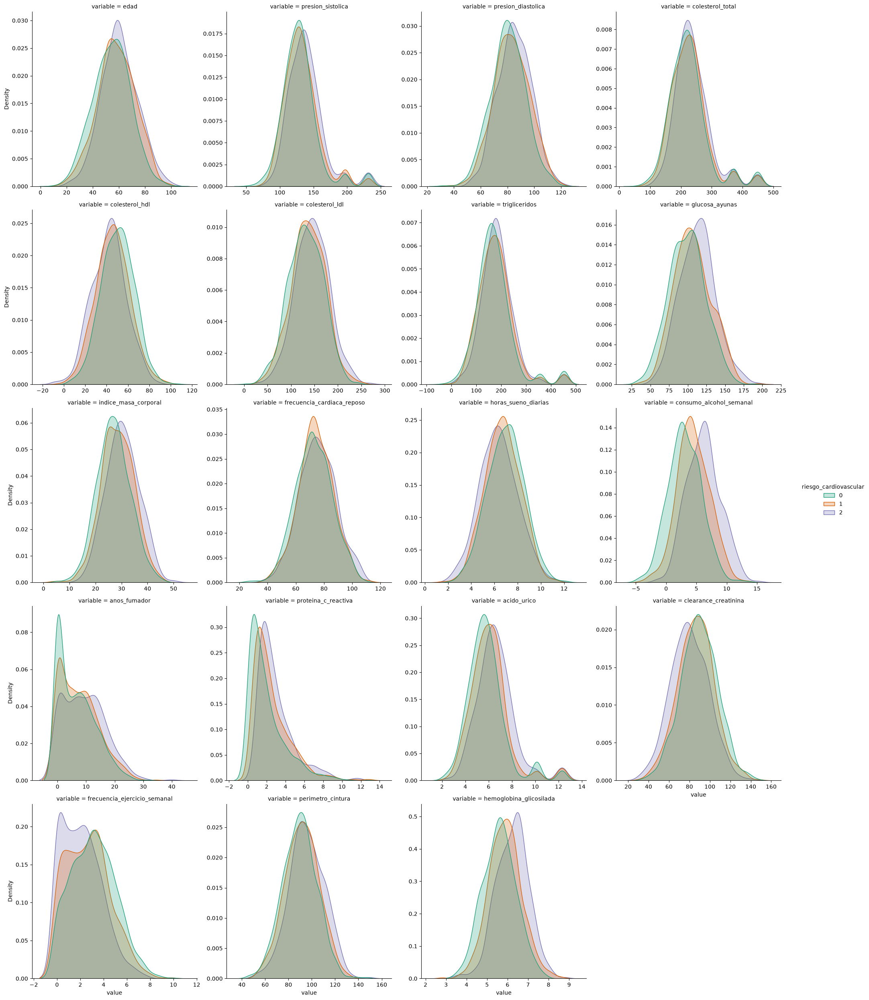

In [41]:
# Visualizar solo distribuciones de clases

datos_continuos = datos[variables_continuas].melt(id_vars='riesgo_cardiovascular')
sns.displot(
    data=datos_continuos, x="value", hue="riesgo_cardiovascular", col="variable", 
    kind="kde", common_norm=False, fill=True, col_wrap=4, palette="Dark2",
    facet_kws={'sharex': False, 'sharey': False}
)


### 1.3.2. Variables binarias

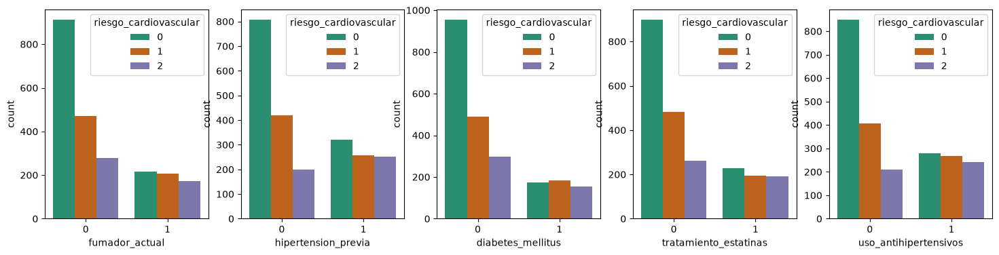

In [42]:
variables_binarias = ["fumador_actual", "hipertension_previa", "diabetes_mellitus", "tratamiento_estatinas", "uso_antihipertensivos"]

fig, axes = plt.subplots(1, 5, figsize=(18, 4))
for i, col in enumerate(variables_binarias):
    sns.countplot(data=datos, x=col, hue='riesgo_cardiovascular', ax=axes[i], palette="Dark2")

plt.show()


### 1.3.3 Variables str

C:\Users\rodma\AppData\Local\Temp\ipykernel_1528\380011535.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=datos, x=variable, palette="Dark2")
C:\Users\rodma\AppData\Local\Temp\ipykernel_1528\380011535.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=datos, x=variable, palette="Dark2")
C:\Users\rodma\AppData\Local\Temp\ipykernel_1528\380011535.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=datos, x=variable, palette="Dark2")


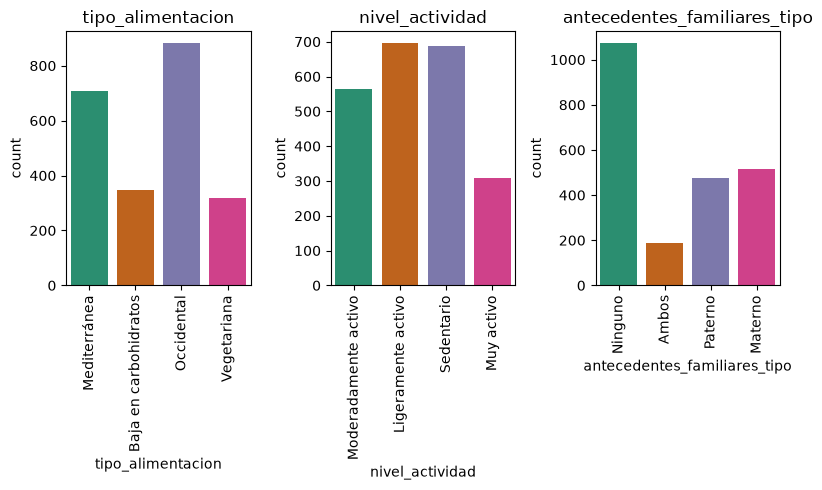

In [43]:
variables_categoricas = [
    "tipo_alimentacion",
    "nivel_actividad",
    "antecedentes_familiares_tipo"
]

plt.figure(figsize=(8, 5))

for i, variable in enumerate(variables_categoricas):
    plt.subplot(1, 3, i+1)
    sns.countplot(data=datos, x=variable, palette="Dark2")
    plt.title(variable)
    plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

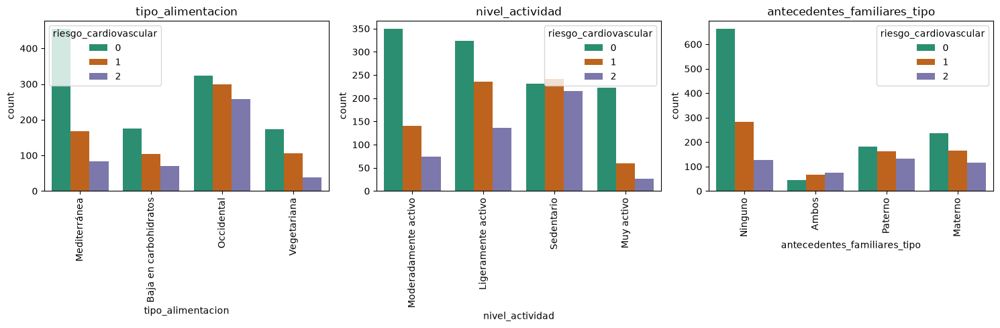

In [44]:
# Gráfico de variables str desagregado por clases de riesgo cardiovascular

variables_categoricas = [
    "tipo_alimentacion",
    "nivel_actividad",
    "antecedentes_familiares_tipo"
]

plt.figure(figsize=(15, 5))

for i, variable in enumerate(variables_categoricas):
    plt.subplot(1, 3, i+1)
    sns.countplot(data=datos, x=variable, hue="riesgo_cardiovascular", palette="Dark2")
    plt.title(variable)
    plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

**Observaciones**
- En variables continuas las clases parecen solaparse y no ser linealmente separables. Se identifican además para las variables `presion_sistolica`, `colesterol_total`, `trigliceridos`, `acido_urico` valores de instancias constantes fuera de la nube de puntos del scatterplot que se deben analizar a profundidad.
- En varaibles binarias se evidencia que la clase mayoritaria es riesgo = 0 (bajo riesgo)
- En variables de texto se identifican nuevas categorías posibles

## 1.4. Clases

Ver cuántos pacientes hay en cada clase de riesgo y en qué porcentaje, para comprobar si el dataset está desbalanceado.

riesgo_cardiovascular
0    1127
1     676
2     451
Name: count, dtype: int64

riesgo_cardiovascular
0    0.500000
1    0.299911
2    0.200089
Name: proportion, dtype: float64

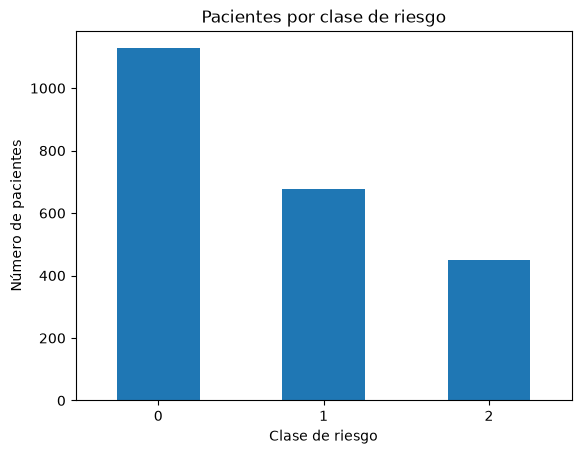

In [45]:
count_classes = datos['riesgo_cardiovascular'].value_counts(sort=True)
display(count_classes)
count_classes.plot(kind = 'bar', rot=0)

display(datos['riesgo_cardiovascular'].value_counts(normalize=True))


plt.title("Pacientes por clase de riesgo")
plt.xlabel("Clase de riesgo")
plt.ylabel("Número de pacientes");

El dataset está desbalanceado: la clase 0 (bajo riesgo) tiene 1127 pacientes (50 %), la clase 1 (riesgo moderado) 676 (30 %) y la clase 2 (alto riesgo) 451 (20 %), siendo el alto riesgo la clase minoritaria.



## 1.5. Valores faltantes

Ver el porcentaje de datos nulos y ver como se distribuyen entre clases de riesgo y pacientes.

In [46]:
# porcentaje de nulos por columna
display(datos.isnull().mean().mul(100))

# porcentaje de nulos por clase de riesgo
display(datos.isnull().groupby(datos['riesgo_cardiovascular']).mean().mul(100))

# nulos por paciente
datos.isnull().sum(axis=1).value_counts()

edad                            0.000000
presion_sistolica               0.000000
presion_diastolica              0.000000
colesterol_total                0.000000
colesterol_hdl                  0.000000
colesterol_ldl                  5.989352
trigliceridos                   0.000000
glucosa_ayunas                  4.968944
indice_masa_corporal            0.000000
frecuencia_cardiaca_reposo      0.000000
horas_sueno_diarias             7.985803
consumo_alcohol_semanal         0.000000
anos_fumador                    0.000000
proteina_c_reactiva             6.965395
acido_urico                     0.000000
clearance_creatinina            0.000000
frecuencia_ejercicio_semanal    0.000000
perimetro_cintura               0.000000
hemoglobina_glicosilada         0.000000
fumador_actual                  0.000000
hipertension_previa             0.000000
diabetes_mellitus               0.000000
tratamiento_estatinas           0.000000
uso_antihipertensivos           0.000000
tipo_alimentacio

,edad,presion_sistolica,presion_diastolica,colesterol_total,colesterol_hdl,colesterol_ldl,trigliceridos,glucosa_ayunas,indice_masa_corporal,frecuencia_cardiaca_reposo,...,hemoglobina_glicosilada,fumador_actual,hipertension_previa,diabetes_mellitus,tratamiento_estatinas,uso_antihipertensivos,tipo_alimentacion,nivel_actividad,antecedentes_familiares_tipo,riesgo_cardiovascular
riesgo_cardiovascular,,,,,,,,,,,,,,,,,,,,,
0,0.0,0.0,0.0,0.0,0.0,6.388642,0.0,4.436557,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,6.065089,0.0,4.585799,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,4.878049,0.0,6.873614,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


0    1721
1     484
2      47
3       2
Name: count, dtype: int64

Hay nulos en 4 variables: `colesterol_ldl` (6 %), `glucosa_ayunas` (5 %), `horas_sueno_diarias` (8 %) y `proteina_c_reactiva` (7 %) y no parece que la aprición de datos nulos dependa del tipo de paciente. Además, al ser escasos, con sustituirlos por un valor razonable, será suficiente.


## 1.6. Calidad de los datos

Comprobar los valores anómalos obtenidos en `describe()` (negativos, valores sin sentido clínico, incoherencias entre variables) y los valores que se repiten de forma sospechosa.

In [47]:
(datos[variables_continuas] < 0).sum()

edad                              0
presion_sistolica                 0
presion_diastolica                0
colesterol_total                  0
colesterol_hdl                    4
colesterol_ldl                    0
trigliceridos                     4
glucosa_ayunas                    0
indice_masa_corporal              0
frecuencia_cardiaca_reposo        0
horas_sueno_diarias               0
consumo_alcohol_semanal         177
anos_fumador                      0
proteina_c_reactiva               0
acido_urico                       0
clearance_creatinina              0
frecuencia_ejercicio_semanal      0
perimetro_cintura                 0
hemoglobina_glicosilada           0
riesgo_cardiovascular             0
dtype: int64

In [48]:
# valores sin sentido clínico
print('Pacientes menores de 18 años:', (datos['edad'] < 18).sum())
print('Pacientes con IMC menor de 12:', (datos['indice_masa_corporal'] < 12).sum())
print('Pacientes con más de 7 días de ejercicio a la semana:', (datos['frecuencia_ejercicio_semanal'] > 7).sum())

Pacientes menores de 18 años: 4
Pacientes con IMC menor de 12: 13
Pacientes con más de 7 días de ejercicio a la semana: 41


In [49]:
# valores incoherentes
print('Presión sistólica menor o igual que la diastólica:', (datos['presion_sistolica'] <= datos['presion_diastolica']).sum())
print('HDL + LDL mayor que el colesterol total:', ((datos['colesterol_hdl'] + datos['colesterol_ldl']) > datos['colesterol_total']).sum())
print('Años fumando mayores que la edad:', (datos['anos_fumador'] > datos['edad']).sum())

Presión sistólica menor o igual que la diastólica: 44
HDL + LDL mayor que el colesterol total: 559
Años fumando mayores que la edad: 1


In [50]:
# comprobar que las variables corresponden al tipo de datos que deben tener
print('Pacientes con la edad con decimales:', (datos['edad'] % 1 != 0).sum())
print('Pacientes con los días de ejercicio con decimales:', (datos['frecuencia_ejercicio_semanal'] % 1 != 0).sum())

for col in ['fumador_actual', 'hipertension_previa', 'diabetes_mellitus', 'tratamiento_estatinas', 'uso_antihipertensivos', 'riesgo_cardiovascular']:
    print(col, datos[col].unique())

for col in ['tipo_alimentacion', 'nivel_actividad', 'antecedentes_familiares_tipo']:
    display(datos[col].value_counts(dropna=False))

Pacientes con la edad con decimales: 2046
Pacientes con los días de ejercicio con decimales: 1836
fumador_actual [1 0]
hipertension_previa [1 0]
diabetes_mellitus [1 0]
tratamiento_estatinas [0 1]
uso_antihipertensivos [1 0]
riesgo_cardiovascular [2 1 0]


tipo_alimentacion
Occidental               881
Mediterránea             706
Baja en carbohidratos    349
Vegetariana              318
Name: count, dtype: int64

nivel_actividad
Ligeramente activo      695
Sedentario              687
Moderadamente activo    563
Muy activo              309
Name: count, dtype: int64

antecedentes_familiares_tipo
Ninguno    1072
Materno     517
Paterno     477
Ambos       188
Name: count, dtype: int64

In [51]:
# valores que se repiten
for col in ['presion_sistolica', 'colesterol_total', 'trigliceridos', 'acido_urico']:
    print(col)
    display(datos[col].value_counts().head(3))

presion_sistolica


presion_sistolica
196.95    59
231.36    53
133.70    10
Name: count, dtype: int64

colesterol_total


colesterol_total
371.24    74
448.59    61
242.20     8
Name: count, dtype: int64

trigliceridos


trigliceridos
452.70    54
357.56    36
177.60     6
Name: count, dtype: int64

acido_urico


acido_urico
10.13    61
12.29    51
5.83     16
Name: count, dtype: int64

**Valores imposibles o sin sentido clínico**
- Hay valores negativos en `consumo_alcohol_semanal` (177), `colesterol_hdl` (4) y `trigliceridos` (4).
- También se ve que 4 pacientes son menores de 18 años, 13 tienen un IMC menor de 12 y 41 hacen más de 7 días de ejercicio a la semana.

**Incoherencias entre variables**
- 44 pacientes tienen una presión sistólica menor o igual a la diastólica, que es siempre mayor y hay un paciente que lleva más años fumando que la edad que tiene.
- En 559 pacientes (alrededor del 25 %), la suma HDL y LDL es mayor que el colesterol total.
- `edad` (años cumplidos) y `frecuencia_ejercicio_semanal` (días a la semana) deberían ser variables enteras, pero en casi todos los pacientes, tienen decimales (2046 y 1836 de 2254).

**Valores repetidos**
- En `presion_sistolica` (196.95 y 231.36), `colesterol_total` (371.24 y 448.59), `trigliceridos` (452.7 y 357.56) y `acido_urico` (10.13 y 12.29) hay dos valores que se repiten entre 36 y 74 veces, mientras que el siguiente valor más frecuente se repite como mucho 16 veces. Al ser valores decimales, es improbable que haya ocurrido de forma natural y podrían ser valores sustituidos (antiguos nulos).
